<a href="https://colab.research.google.com/github/Usermer/-Medical-Appointment-Management-System/blob/main/Chapter_15_Processing_Sequences_Using_RNNs.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [49]:
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.tsa.arima.model import ARIMA

In [50]:
df=pd.read_csv('/content/CTA_-_Ridership_-_Daily_Boarding_Totals_20250830.csv')
df.head()

,service_date,day_type,bus,rail_boardings,total_rides
0,01/01/2001,U,"297,192","126,455","423,647"
1,01/02/2001,W,"780,827","501,952","1,282,779"
2,01/03/2001,W,"824,923","536,432","1,361,355"
3,01/04/2001,W,"870,021","550,011","1,420,032"
4,01/05/2001,W,"890,426","557,917","1,448,343"


In [51]:
df.shape

(8947, 5)

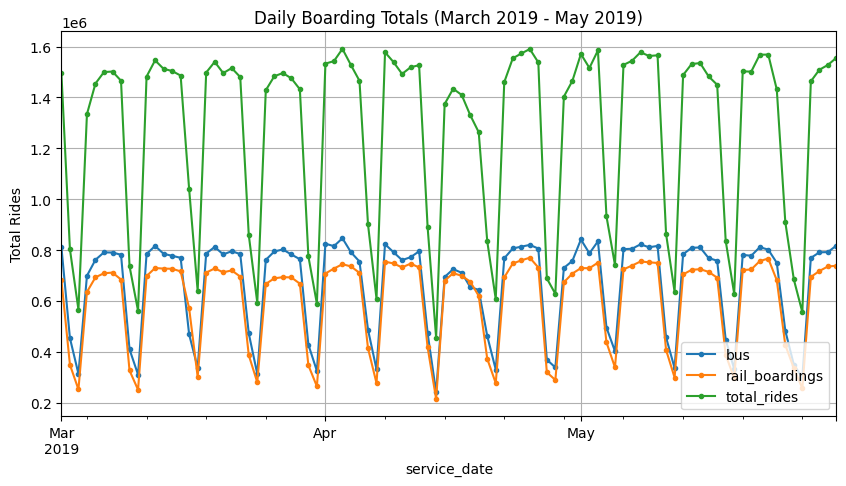

In [52]:
# Convert service_date to datetime and set as index
df['service_date'] = pd.to_datetime(df['service_date'])
df_indexed = df.set_index('service_date').sort_index()

# Clean and convert the target columns to numeric using .apply()
cols_to_clean = ['total_rides', 'rail_boardings', 'bus']
df_indexed[cols_to_clean] = df_indexed[cols_to_clean].apply(lambda x: x.str.replace(',', '').astype(float))

# Now you can slice using the datetime index and plot
df_indexed['2019-03':'2019-05'].plot(grid=True, marker='.', figsize=(10, 5))
plt.title('Daily Boarding Totals (March 2019 - May 2019)')
plt.ylabel('Total Rides')
plt.show()

In [53]:
df_indexed.drop(columns=['total_rides'])

,day_type,bus,rail_boardings
service_date,,,
2001-01-01,U,297192.0,126455.0
2001-01-02,W,780827.0,501952.0
2001-01-03,W,824923.0,536432.0
2001-01-04,W,870021.0,550011.0
2001-01-05,W,890426.0,557917.0
...,...,...,...
2025-06-26,W,561301.0,471300.0
2025-06-27,W,543140.0,416639.0
2025-06-28,A,427366.0,337560.0


In [54]:
diff_7=df_indexed[['bus',"rail_boardings"]].diff(7)["2019-03":"2019-05"]

### Understanding the `.diff(7)` Function and Output

#### 1. What does `.diff(7)` do?
By default, `.diff()` (equivalent to `.diff(1)`) subtracts the value of the previous day from the current day:
$$\text{difference} = \text{value}_{t} - \text{value}_{t-1}$$

When you use **`.diff(7)`**, you are calculating a **7-day seasonal difference**. It subtracts the value from exactly one week (7 days) ago from today's value:
$$\text{difference} = \text{value}_{t} - \text{value}_{t-7}$$

#### 2. Why is it useful here?
Transit ridership is highly seasonal and depends heavily on the day of the week (e.g., weekdays have high commute ridership, while weekends have much lower ridership).

Using `.diff(7)` **removes this weekly seasonality**. Instead of seeing the dramatic ups and downs of weekends vs. weekdays, you see whether ridership on a specific day (e.g., this Tuesday) is higher or lower than it was on the *same day* last week (last Tuesday).

#### 3. Interpreting the Output
* **Positive values** mean ridership increased compared to the same day of the week in the prior week.
* **Negative values** mean ridership decreased compared to the same day of the week in the prior week.
* **Values near 0** mean ridership remained stable week-over-week.

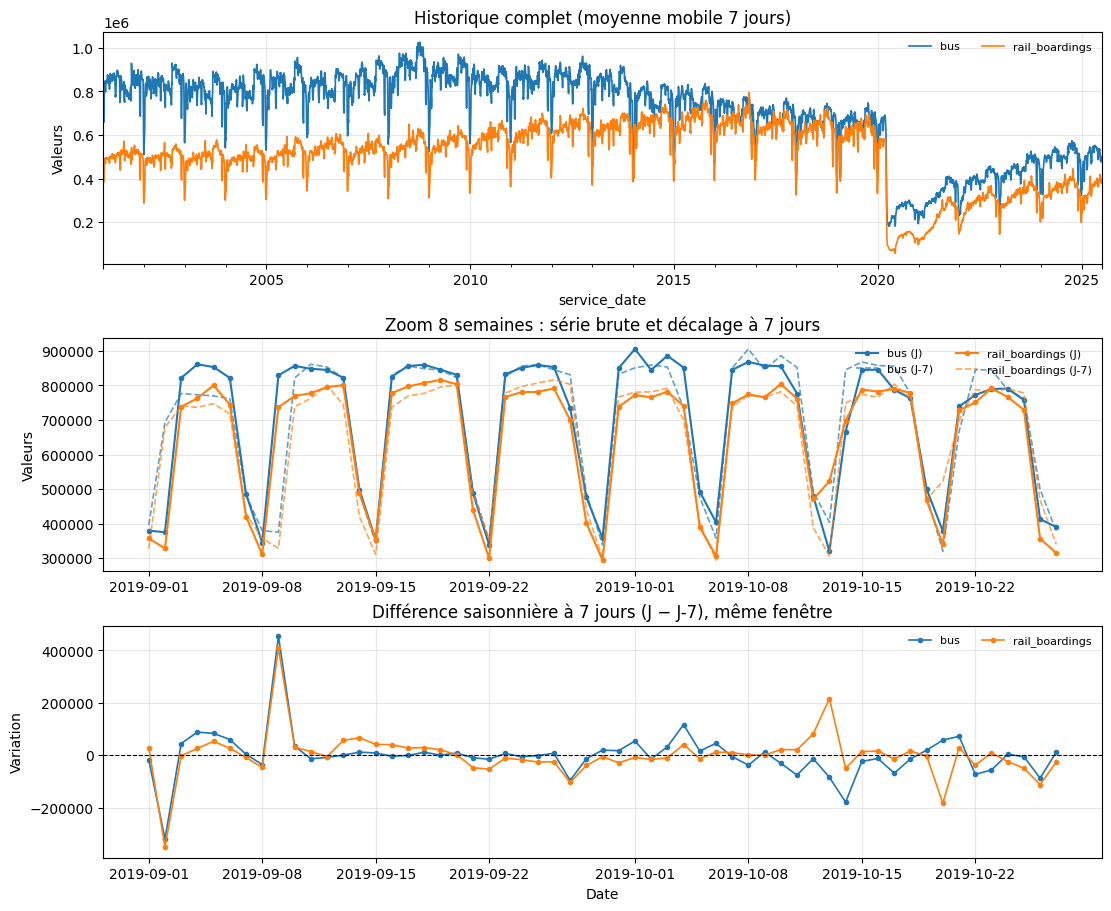

In [55]:
import matplotlib.pyplot as plt

cols = ['bus', 'rail_boardings']
colors = {'bus': 'tab:blue', 'rail_boardings': 'tab:orange'}

df_num = df_indexed[cols]
diff_7 = df_num.diff(7)

# Fenêtre de zoom : 8 semaines (8 cycles hebdomadaires), à adapter
zoom = df_num.loc['2019-09-01':'2019-10-27']

fig, axs = plt.subplots(3, 1, figsize=(11, 9), constrained_layout=True)

# 1) Historique complet : moyenne mobile sur 7 jours (la saisonnalité hebdo disparaît)
for c in cols:
    df_num[c].rolling(7).mean().plot(ax=axs[0], color=colors[c], lw=1.2, label=c)
axs[0].set_title("Historique complet (moyenne mobile 7 jours)")
axs[0].set_ylabel("Valeurs")

# 2) Zoom : brut vs J-7 (le décalage se superpose au motif hebdomadaire)
for c in cols:
    axs[1].plot(zoom.index, zoom[c], color=colors[c], lw=1.5, marker='o', ms=3, label=f"{c} (J)")
    axs[1].plot(zoom.index, df_num[c].shift(7).loc[zoom.index], color=colors[c],
                lw=1.2, ls='--', alpha=0.7, label=f"{c} (J-7)")
axs[1].set_title("Zoom 8 semaines : série brute et décalage à 7 jours")
axs[1].set_ylabel("Valeurs")

# 3) Différence saisonnière sur la même fenêtre
for c in cols:
    axs[2].plot(zoom.index, diff_7[c].loc[zoom.index], color=colors[c], lw=1.2, marker='o', ms=3, label=c)
axs[2].axhline(0, color='black', lw=0.8, ls='--')
axs[2].set_title("Différence saisonnière à 7 jours (J − J-7), même fenêtre")
axs[2].set_ylabel("Variation")
axs[2].set_xlabel("Date")

for ax in axs:
    ax.grid(True, alpha=0.3)
    ax.legend(loc='upper right', ncol=2, fontsize=8, frameon=False)

plt.show()

In [56]:
diff_7.abs().mean()

,0
bus,59147.948658
rail_boardings,43066.245973


In [57]:
targets=df_indexed[["bus","rail_boardings"]]["2019-03":"2019-05"]
(diff_7/targets).abs().mean()

,0
bus,0.082938
rail_boardings,0.089948


In [58]:
#yearly seasonality
period = slice("2001", "2019")
# Select only numeric columns first to avoid aggregation errors on string/object columns
df_monthly = df_indexed[['bus', 'rail_boardings']].resample("ME").mean()
rolling_avg = df_monthly.loc[period].rolling(window=12).mean()

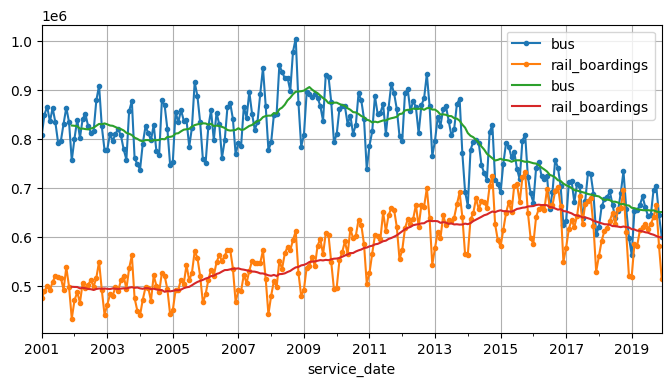

In [59]:
fig,ax=plt.subplots(figsize=(8,4))
df_monthly[period].plot(ax=ax,marker=".")
rolling_avg .plot(ax=ax,grid=True)
plt.show()

### Understanding the ARMA Model

An **ARMA (AutoRegressive Moving Average)** model is a classic statistical framework used to analyze and forecast stationary time series data. It consists of two complementary components:

#### 1. The AR (AutoRegressive) Part: "Past Values"
* **Concept**: This component models the relationship between the current observation ($Y_t$) and its own immediate past values ($Y_{t-1}, Y_{t-2}$, etc.).
* **Formula**: $Y_t = c + \phi_1 Y_{t-1} + \phi_2 Y_{t-2} + \dots + \epsilon_t$
* **Context**: If transit ridership is high on a Monday, it is likely to stay relatively high on Tuesday. The AR term captures this momentum.

#### 2. The MA (Moving Average) Part: "Past Errors"
* **Concept**: This component models the current observation as a function of past prediction errors or random shocks (unexpected changes like storms, holidays, or disruptions, denoted by $\epsilon_{t-1}$, etc.).
* **Formula**: $Y_t = \mu + \theta_1 \epsilon_{t-1} + \theta_2 \epsilon_{t-2} + \dots + \epsilon_t$
* **Context**: If an unexpected blizzard drops ridership significantly today (creating a large negative shock $\epsilon_t$), the MA term propagates a portion of that shock forward to adjust tomorrow's forecast.

---

### ARMA Parameters: $(p, q)$
An ARMA model is defined by its orders, written as **$\\text{ARMA}(p, q)$**:
* **$p$ (AR order)**: The number of lag observations to include (how far back in time we look for past values).
* **$q$ (MA order)**: The size of the moving average window (how far back we track past random errors).

### Stationarity Requirement
ARMA models assume the time series is **stationary** (its mean, variance, and autocorrelation structure are constant over time). Because raw transit ridership has a clear upward/downward trend and prominent weekly seasonality, we first apply differencing (like your 7-day seasonal difference, `diff_7`) to achieve stationarity.